BÀI 4: Iris với Neural Network và k-fold cross validation (k = 10)

Cell 0: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

Câu a) Đọc bộ dữ liệu Iris từ sklearn

In [2]:
print("Lê Anh Pha - 6451071056")

iris = load_iris()
print("Đã đọc xong bộ dữ liệu Iris")
print("Các thuộc tính:", iris.feature_names)
print("Các lớp:", iris.target_names)
print("data.shape:", iris.data.shape, "| target.shape:", iris.target.shape)

Lê Anh Pha - 6451071056
Đã đọc xong bộ dữ liệu Iris
Các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Các lớp: ['setosa' 'versicolor' 'virginica']
data.shape: (150, 4) | target.shape: (150,)


Câu b) Chuẩn hóa dữ liệu về đoạn [0,1]

In [3]:
print("Lê Anh Pha - 6451071056")

X = iris.data
Y = iris.target

# Lưu max từng cột để chuẩn hóa mẫu mới ở câu g
max_values = X.max(axis=0)
print("Giá trị lớn nhất mỗi cột:", max_values)

X = X / max_values

print("Min sau chuẩn hóa:", X.min(axis=0))
print("Max sau chuẩn hóa:", X.max(axis=0))

Lê Anh Pha - 6451071056
Giá trị lớn nhất mỗi cột: [7.9 4.4 6.9 2.5]
Min sau chuẩn hóa: [0.5443038  0.45454545 0.14492754 0.04      ]
Max sau chuẩn hóa: [1. 1. 1. 1.]


Câu c) Định nghĩa hàm create_model

In [4]:
print("Lê Anh Pha - 6451071056")

def create_model():
    model = Sequential([
        Input(shape=(4,)),                 # 4 thuộc tính
        Dense(10, activation='relu'),      # hidden layer 1: 10 neuron
        Dense(20, activation='relu'),      # hidden layer 2: 20 neuron
        Dense(3, activation='softmax')     # output: 3 lớp
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

create_model().summary()

Lê Anh Pha - 6451071056


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

Câu d) Huấn luyện bằng k-fold cross validation (k = 10)

In [5]:
print("Lê Anh Pha - 6451071056")

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
acc_per_fold = []
prec_per_fold = []     # macro
rec_per_fold = []      # macro
f1_per_fold = []       # macro

# Lưu precision/recall/f1 của TỪNG LỚP ở mỗi fold (dùng cho câu f)
prec_class_per_fold = []
rec_class_per_fold = []
f1_class_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(X):
    model = create_model()

    X_train_fold, X_val_fold = X[train_index], X[val_index]
    y_train_fold, y_val_fold = Y[train_index], Y[val_index]

    model.fit(X_train_fold, y_train_fold, epochs=100, batch_size=1, verbose=0)

    # Lưu mô hình sau mỗi fold
    models.append(model)

    # Dự đoán trên tập validation của fold
    y_pred = np.argmax(model.predict(X_val_fold, verbose=0), axis=1)

    acc = accuracy_score(y_val_fold, y_pred)

    # Trung bình macro (3 lớp)
    p, r, f, _ = precision_recall_fscore_support(
        y_val_fold, y_pred, average='macro', labels=[0, 1, 2], zero_division=0)

    # Từng lớp
    p_c, r_c, f_c, _ = precision_recall_fscore_support(
        y_val_fold, y_pred, average=None, labels=[0, 1, 2], zero_division=0)

    acc_per_fold.append(acc)
    prec_per_fold.append(p)
    rec_per_fold.append(r)
    f1_per_fold.append(f)
    prec_class_per_fold.append(p_c)
    rec_class_per_fold.append(r_c)
    f1_class_per_fold.append(f_c)

    print(f"Fold {fold_no:2d}: Accuracy = {acc:.4f} | Precision = {p:.4f} | Recall = {r:.4f} | F1-score = {f:.4f}")
    fold_no += 1

Lê Anh Pha - 6451071056
Fold  1: Accuracy = 0.9333 | Precision = 0.9167 | Recall = 0.9444 | F1-score = 0.9221
Fold  2: Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000 | F1-score = 1.0000
Fold  3: Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000 | F1-score = 1.0000
Fold  4: Accuracy = 0.9333 | Precision = 0.9524 | Recall = 0.9333 | F1-score = 0.9373


Fold  5: Accuracy = 0.9333 | Precision = 0.9333 | Recall = 0.9333 | F1-score = 0.9259


Fold  6: Accuracy = 0.8667 | Precision = 0.8667 | Recall = 0.8889 | F1-score = 0.8500
Fold  7: Accuracy = 0.9333 | Precision = 0.9524 | Recall = 0.9167 | F1-score = 0.9267
Fold  8: Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000 | F1-score = 1.0000
Fold  9: Accuracy = 0.9333 | Precision = 0.9444 | Recall = 0.9333 | F1-score = 0.9327
Fold 10: Accuracy = 1.0000 | Precision = 1.0000 | Recall = 1.0000 | F1-score = 1.0000


Câu e) Average Accuracy, Recall, Precision, F1-score

In [6]:
print("Lê Anh Pha - 6451071056")

print(f"Average Accuracy : {np.mean(acc_per_fold):.4f}")
print(f"Average Recall   : {np.mean(rec_per_fold):.4f}")
print(f"Average Precision: {np.mean(prec_per_fold):.4f}")
print(f"Average F1-score : {np.mean(f1_per_fold):.4f}")

Lê Anh Pha - 6451071056
Average Accuracy : 0.9533
Average Recall   : 0.9550
Average Precision: 0.9566
Average F1-score : 0.9495


Câu f) Average Recall, Precision, F1-score cho từng class

In [7]:
print("Lê Anh Pha - 6451071056")

# Mỗi mảng có shape (10, 3): 10 fold x 3 lớp -> lấy trung bình theo trục fold
avg_prec_class = np.mean(prec_class_per_fold, axis=0)
avg_rec_class = np.mean(rec_class_per_fold, axis=0)
avg_f1_class = np.mean(f1_class_per_fold, axis=0)

bang_class = pd.DataFrame({
    'Class': iris.target_names,
    'Average Precision': avg_prec_class,
    'Average Recall': avg_rec_class,
    'Average F1-score': avg_f1_class
})
print(bang_class.round(4).to_string(index=False))

Lê Anh Pha - 6451071056
     Class  Average Precision  Average Recall  Average F1-score
    setosa             1.0000           1.000            1.0000
versicolor             0.9490           0.925            0.9287
 virginica             0.9207           0.940            0.9197


Câu g) Dùng các mô hình có F1-score tốt nhất để dự đoán 3 mẫu mới

In [8]:
print("Lê Anh Pha - 6451071056")

# Tìm F1 cao nhất; có thể nhiều fold cùng đạt giá trị này nên lấy tất cả
best_f1 = np.max(f1_per_fold)
best_indexes = [i for i, f in enumerate(f1_per_fold) if np.isclose(f, best_f1)]
print(f"F1-score tốt nhất = {best_f1:.4f}, đạt ở các fold: {[i + 1 for i in best_indexes]}")

# 3 mẫu mới, chuẩn hóa bằng CÙNG max của dữ liệu gốc
mau_moi = np.array([[6.2, 2.9, 4.3, 1.3],
                    [5.1, 3.5, 1.4, 0.2],
                    [7.3, 2.8, 6.4, 2.1]])
mau_moi = mau_moi / max_values

for i in best_indexes:
    pred = np.argmax(models[i].predict(mau_moi, verbose=0), axis=1)
    print(f"\nMô hình Fold {i + 1}:")
    for k in range(3):
        print(f"  Mẫu {k + 1}: {iris.target_names[pred[k]]}")

Lê Anh Pha - 6451071056
F1-score tốt nhất = 1.0000, đạt ở các fold: [2, 3, 8, 10]

Mô hình Fold 2:
  Mẫu 1: versicolor
  Mẫu 2: setosa
  Mẫu 3: virginica

Mô hình Fold 3:
  Mẫu 1: versicolor
  Mẫu 2: setosa
  Mẫu 3: virginica

Mô hình Fold 8:
  Mẫu 1: versicolor
  Mẫu 2: setosa
  Mẫu 3: virginica

Mô hình Fold 10:
  Mẫu 1: versicolor
  Mẫu 2: setosa
  Mẫu 3: virginica


BÀI 2 (Trang 18-19): Phân tích khách hàng Mall Customers

Cell 0: Import thư viện

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objs as go
import plotly.offline as py

from sklearn.cluster import KMeans
from sklearn import metrics

Câu 1) Nhập dữ liệu, thống kê thông tin cơ bản, xử lý dữ liệu thiếu

In [11]:
print("Lê Anh Pha - 6451071056")

data = pd.read_csv('Mall_Customers.csv')

print("Kích thước dữ liệu:", data.shape)
print("\n5 dòng đầu:")
print(data.head())

print("\nThông tin các cột:")
data.info()

print("\nThống kê mô tả:")
print(data.describe())

# Kiểm tra dữ liệu thiếu
print("\nSố giá trị thiếu mỗi cột:")
print(data.isnull().sum())

# Xử lý dữ liệu thiếu: xóa dòng thiếu (nếu có)
data = data.dropna()
print("\nSau khi xử lý, kích thước dữ liệu:", data.shape)

Lê Anh Pha - 6451071056
Kích thước dữ liệu: (200, 5)

5 dòng đầu:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), ob

Câu 2) Histogram của Tuổi, Thu nhập hằng năm, Số điểm mua sắm

Lê Anh Pha - 6451071056


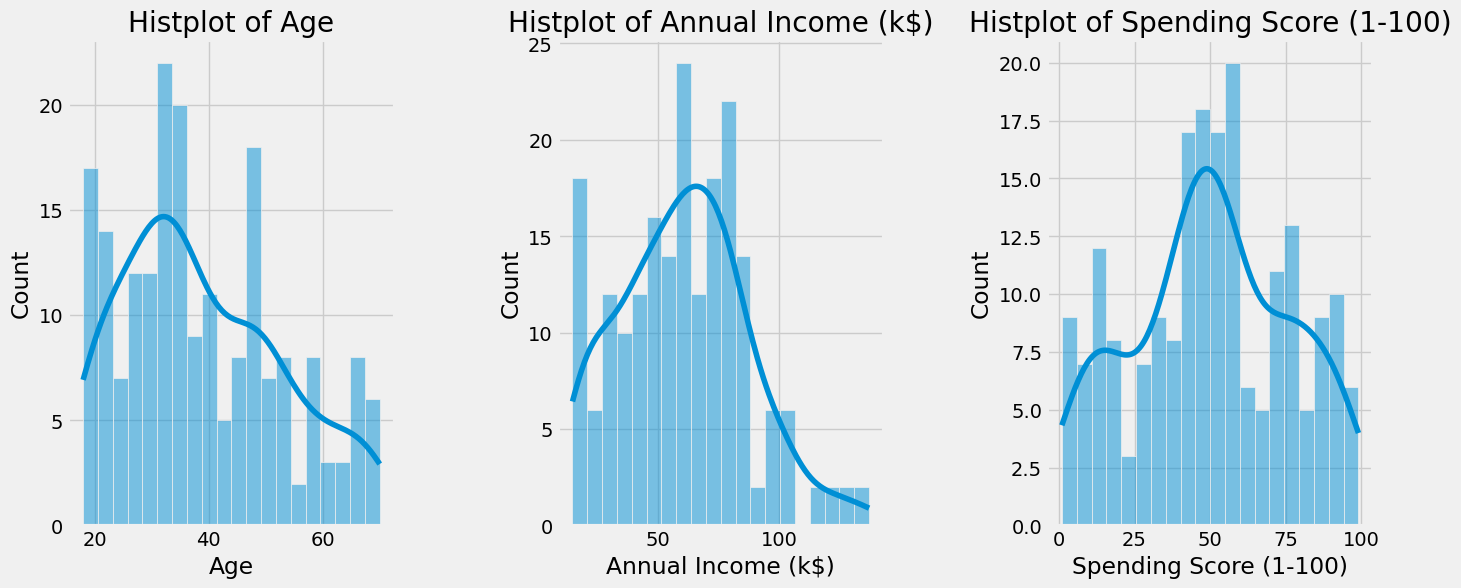

In [12]:
print("Lê Anh Pha - 6451071056")

plt.style.use('fivethirtyeight')
plt.figure(1, figsize=(15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True)   # thay cho distplot (đã lỗi thời)
    plt.title('Histplot of {}'.format(x))
plt.show()

Câu 3) Thống kê số mẫu theo Giới tính

Lê Anh Pha - 6451071056
Gender
Female    112
Male       88
Name: count, dtype: int64


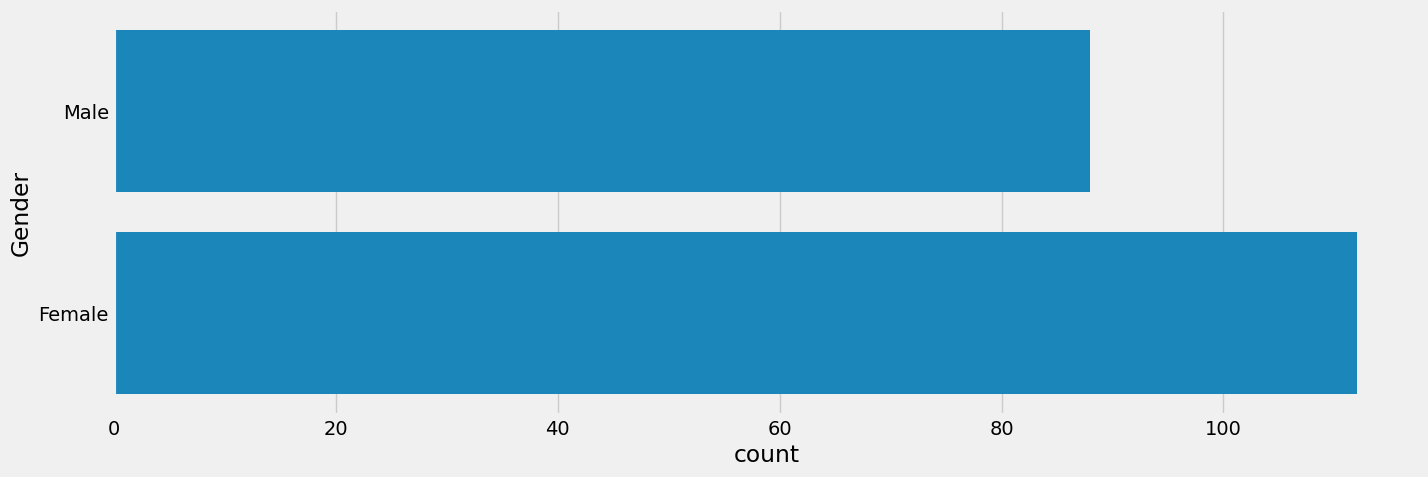

In [13]:
print("Lê Anh Pha - 6451071056")

print(data['Gender'].value_counts())

plt.figure(1, figsize=(15, 5))
sns.countplot(y='Gender', data=data)
plt.show()

Câu 4) Scatter plot: Tuổi và Thu nhập hằng năm theo Giới tính

Lê Anh Pha - 6451071056


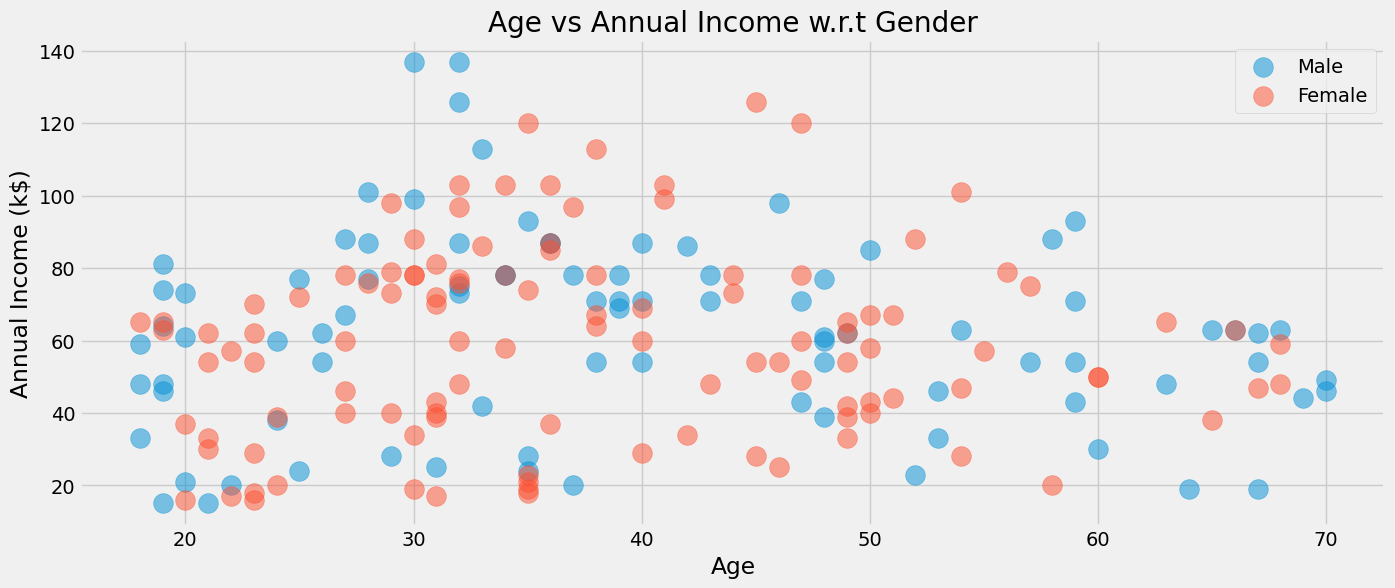

In [14]:
print("Lê Anh Pha - 6451071056")

plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Age', y='Annual Income (k$)', data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Age'), plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income w.r.t Gender')
plt.legend()
plt.show()

Câu 5) Scatter plot: Thu nhập hằng năm và Số điểm mua sắm theo Giới tính

Lê Anh Pha - 6451071056


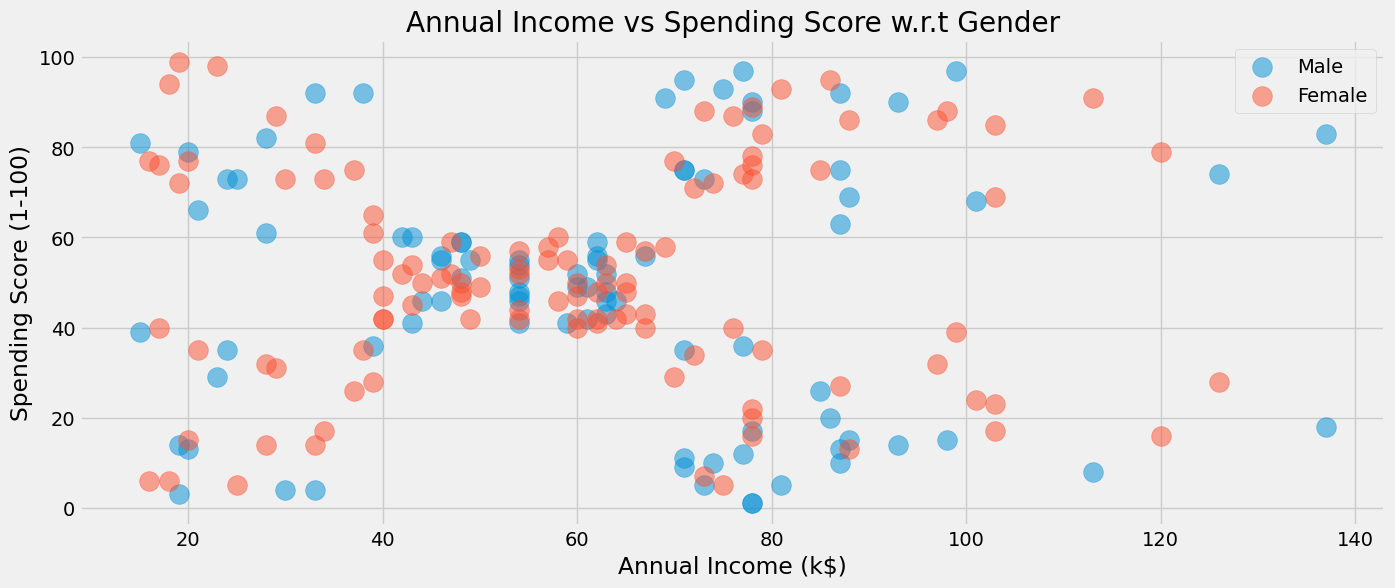

In [15]:
print("Lê Anh Pha - 6451071056")

plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)', data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

Câu 6) Gom cụm theo Tuổi và Số điểm mua sắm: Elbow và k-Means

Cell 1: Elbow method

Lê Anh Pha - 6451071056


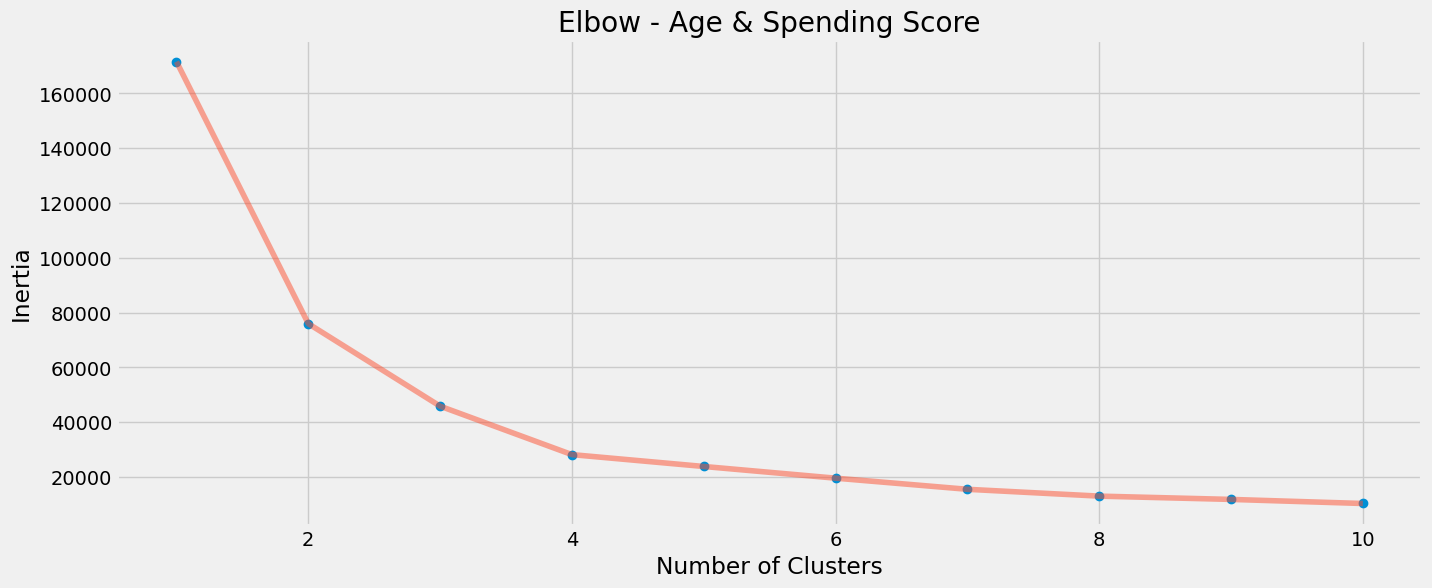

In [16]:
print("Lê Anh Pha - 6451071056")

X1 = data[['Age', 'Spending Score (1-100)']].values

inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Age & Spending Score')
plt.show()

Cell 2: Gom cụm với số cụm xác định từ biểu đồ

In [17]:
print("Lê Anh Pha - 6451071056")

k1 = 4   # số cụm chọn từ vị trí khuỷu tay của biểu đồ trên (sửa nếu biểu đồ của bạn khác)

algorithm = KMeans(n_clusters=k1, init='random', n_init=10, random_state=42)
algorithm.fit(X1)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_

print("Số cụm:", k1)
print("Số điểm mỗi cụm:", np.bincount(labels1))
print("Tâm các cụm:\n", centroids1)

Lê Anh Pha - 6451071056
Số cụm: 4
Số điểm mỗi cụm: [48 48 47 57]
Tâm các cụm:
 [[55.70833333 48.22916667]
 [43.29166667 15.02083333]
 [27.61702128 49.14893617]
 [30.1754386  82.35087719]]


Câu 7) Biểu diễn kết quả gom cụm bằng biểu đồ

Lê Anh Pha - 6451071056


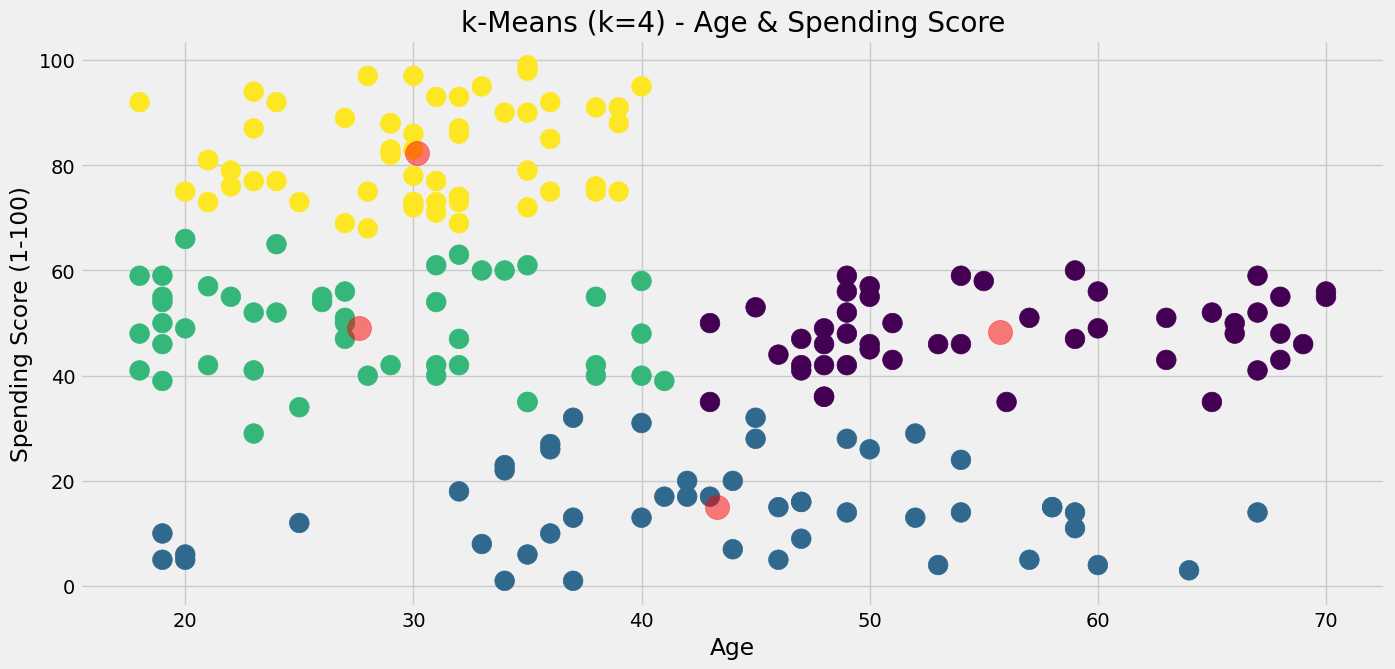

In [18]:
print("Lê Anh Pha - 6451071056")

plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x='Age', y='Spending Score (1-100)', data=data, c=labels1, s=200)
plt.scatter(x=centroids1[:, 0], y=centroids1[:, 1], s=300, c='red', alpha=0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Age')
plt.title(f'k-Means (k={k1}) - Age & Spending Score')
plt.show()

Câu 8) Đánh giá bằng Hệ số Dáng điệu (Silhouette)

In [19]:
print("Lê Anh Pha - 6451071056")

score1 = metrics.silhouette_score(X1, labels1, metric='euclidean')
print(f"Silhouette coefficient (Age & Spending Score, k={k1}): {score1:.4f}")

Lê Anh Pha - 6451071056
Silhouette coefficient (Age & Spending Score, k=4): 0.4997


Câu 9a) Gom cụm theo Thu nhập hằng năm và Số điểm mua sắm (làm lại Câu 6-8)

Cell 1: Elbow

Lê Anh Pha - 6451071056


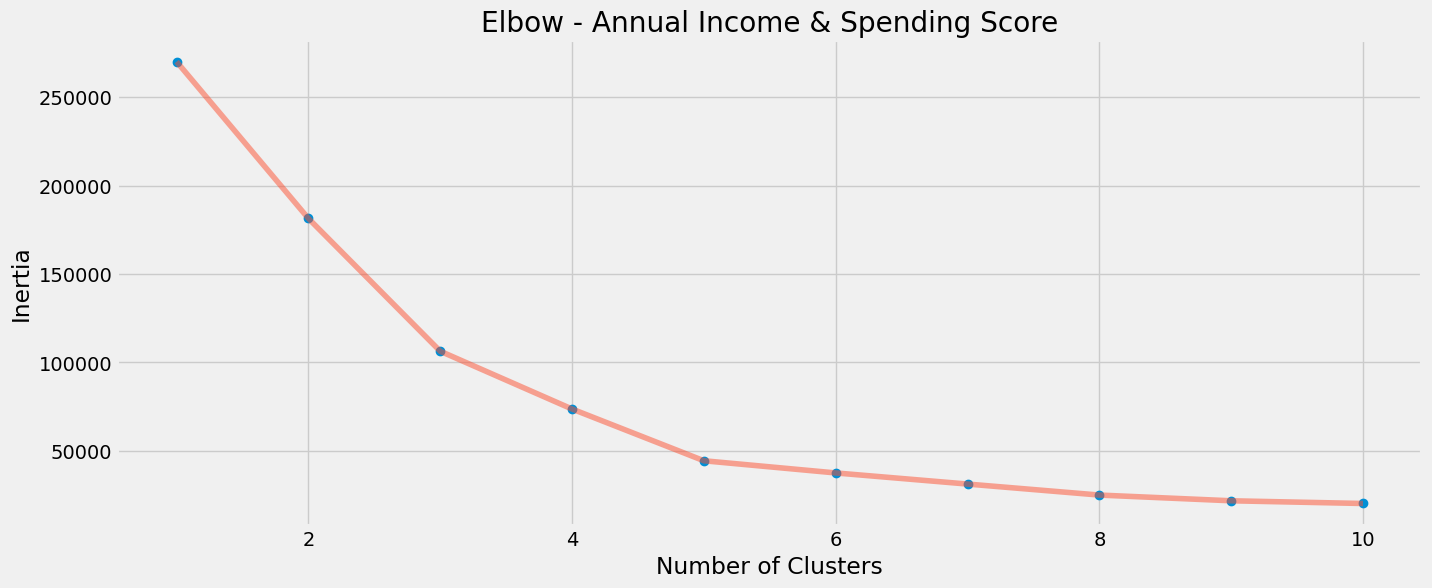

In [20]:
print("Lê Anh Pha - 6451071056")

X2 = data[['Annual Income (k$)', 'Spending Score (1-100)']].values

inertia2 = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X2)
    inertia2.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia2, 'o')
plt.plot(np.arange(1, 11), inertia2, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Annual Income & Spending Score')
plt.show()

Cell 2: Gom cụm, vẽ biểu đồ, Silhouette

Lê Anh Pha - 6451071056


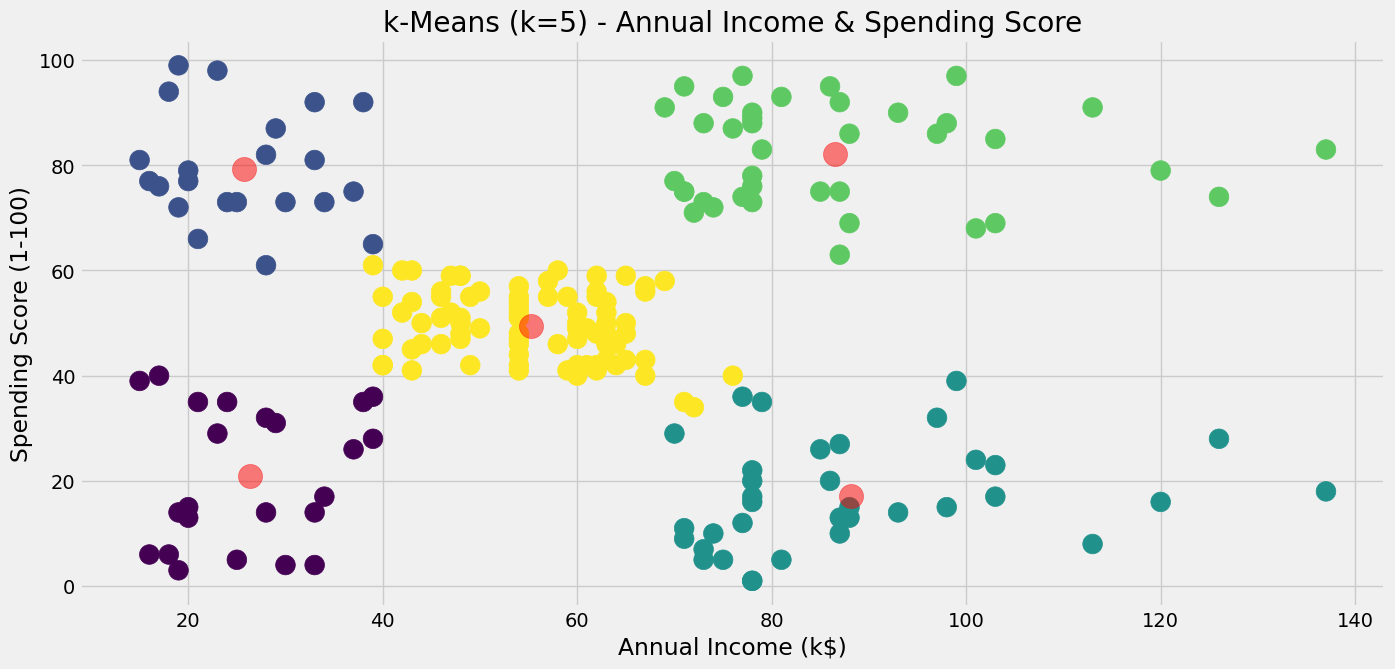

Silhouette coefficient (Annual Income & Spending Score, k=5): 0.5539


In [21]:
print("Lê Anh Pha - 6451071056")

k2 = 5   # chọn theo khuỷu tay của biểu đồ trên (sửa nếu biểu đồ của bạn khác)

algorithm = KMeans(n_clusters=k2, init='random', n_init=10, random_state=42)
algorithm.fit(X2)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

# Biểu đồ kết quả
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)', data=data, c=labels2, s=200)
plt.scatter(x=centroids2[:, 0], y=centroids2[:, 1], s=300, c='red', alpha=0.5)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title(f'k-Means (k={k2}) - Annual Income & Spending Score')
plt.show()

# Silhouette
score2 = metrics.silhouette_score(X2, labels2, metric='euclidean')
print(f"Silhouette coefficient (Annual Income & Spending Score, k={k2}): {score2:.4f}")

Câu 9b) Gom cụm theo Tuổi, Thu nhập hằng năm và Số điểm mua sắm (biểu đồ 3D)

Cell 1: Elbow

Lê Anh Pha - 6451071056


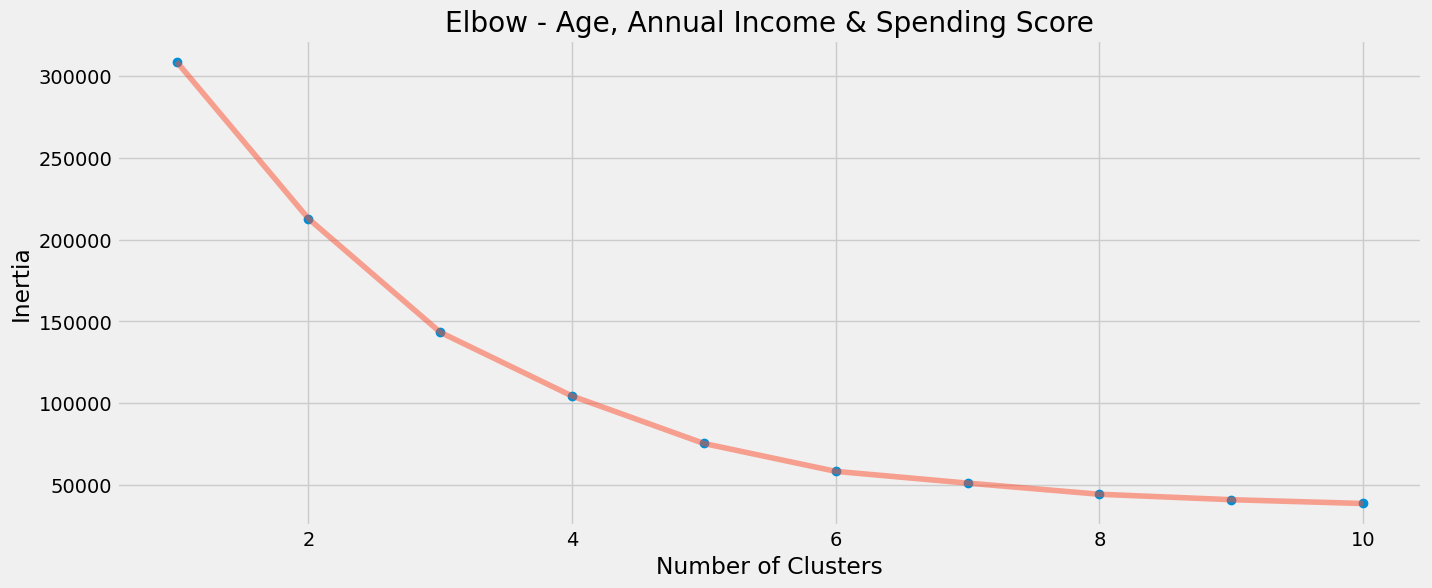

In [22]:
print("Lê Anh Pha - 6451071056")

X3 = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values

inertia3 = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X3)
    inertia3.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia3, 'o')
plt.plot(np.arange(1, 11), inertia3, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow - Age, Annual Income & Spending Score')
plt.show()

Cell 2: Gom cụm và Silhouette

In [23]:
print("Lê Anh Pha - 6451071056")

k3 = 6   # chọn theo khuỷu tay của biểu đồ trên (sửa nếu biểu đồ của bạn khác)

algorithm = KMeans(n_clusters=k3, init='random', n_init=10, random_state=42)
algorithm.fit(X3)
labels3 = algorithm.labels_

print("Số điểm mỗi cụm:", np.bincount(labels3))
score3 = metrics.silhouette_score(X3, labels3, metric='euclidean')
print(f"Silhouette coefficient (3 thuộc tính, k={k3}): {score3:.4f}")

Lê Anh Pha - 6451071056
Số điểm mỗi cụm: [22 39 22 38 35 44]
Silhouette coefficient (3 thuộc tính, k=6): 0.4524


Cell 3: Biểu đồ 3D

In [24]:
print("Lê Anh Pha - 6451071056")

data['label3'] = labels3

trace1 = go.Scatter3d(
    x=data['Age'],
    y=data['Spending Score (1-100)'],
    z=data['Annual Income (k$)'],
    mode='markers',
    marker=dict(color=data['label3'], size=6, opacity=0.8)
)
layout = go.Layout(
    title=f'Clusters (k={k3})',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    )
)
fig = go.Figure(data=[trace1], layout=layout)
fig.show()

Lê Anh Pha - 6451071056
